# Lab 2 — What Did the Campaign Deliver?
Name: Тимофій Погодаєв | Group: КМ-43

## Setup

In [1]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

c:\Users\Tymofii\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]

def broadcast_day(ts):
    return (ts - pd.Timedelta(hours=6)).dt.date

dw = daily_weights[daily_weights["resp_type"].isin(["R", "L"]) & (daily_weights["weight"] > 0)].copy()
dw["bday"] = pd.to_datetime(dw["broadcast_date"]).dt.date

va = viewer_attributes[pd.to_numeric(viewer_attributes["value"], errors="coerce") != 0]
age = pd.to_numeric(va[va["attr_id"] == 300].set_index("respondent_id")["value"], errors="coerce")
women = va.loc[va["attr_id"] == 202, "respondent_id"]

persons = dw.groupby("respondent_id")["weight"].mean().rename("mweight").to_frame()
persons["age"] = age
persons["sex"] = np.where(persons.index.isin(women), "F", "M")

p2 = persons.index
a1849 = persons.index[persons["age"].between(18, 49)]
w1834 = persons.index[(persons["sex"] == "F") & persons["age"].between(18, 34)]

## Task 1.1 — Size

In [3]:
brand_a = commercials[commercials["brand"] == "BRAND_A"]
print("Spots:", len(commercials))
print("Pods:", commercials["pod_id"].nunique())
print("Brands:", commercials["brand"].nunique())
print("Categories:", commercials["category"].nunique())
print("BRAND_A spots:", len(brand_a))
brand_a["network_code"].value_counts().rename_axis("network").reset_index(name="spots")

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,network,spots
0,FNC,40
1,HGTV,39
2,FX,38
3,HIST,37
4,BRAVO,33
5,FOOD,33
6,ABC,29
7,CBS,22
8,NBC,16
9,FOX,13


## Task 1.2 — Ad load

In [4]:
ads = commercials.copy()
ads["clock_hour"] = ads["start_ts"].dt.floor("h")
sec_per_hour = ads.groupby(["network_code", "clock_hour"])["length_sec"].sum()
ad_load = (sec_per_hour.groupby("network_code").mean() / 60).sort_values(ascending=False)
display(ad_load.round(1).rename("ad minutes per hour").reset_index())
print("Heaviest ad load:", ad_load.index[0])

,network_code,ad minutes per hour
0,FNC,15.6
1,BRAVO,13.4
2,HGTV,13.3
3,HIST,13.2
4,FOOD,13.1
5,FX,12.9
6,CBS,12.1
7,ABC,11.8
8,NBC,11.8
9,FOX,11.8


Heaviest ad load: FNC


**Answer:** In local-station hours (early morning, local news, late night) the affiliate, not the network, programs the time and sells the breaks as local avails (Lecture 3, slides 7-8 and 60), so this national log has no ads there. Heaviest load: [NETWORK], [X] min per hour.

## Task 1.3 — Price everything

In [5]:
def clock_to_min(hhmm):
    h, m = hhmm.split(":")
    return int(h) * 60 + int(m) - 360

spots = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id", how="left")
shifted = spots["start_ts"] - pd.Timedelta(hours=6)
spots["weekday"] = shifted.dt.weekday
spots["minute"] = shifted.dt.hour * 60 + shifted.dt.minute

is_program_row = rate_card["program_name"].fillna("") != ""
program_rows = rate_card.loc[is_program_row, ["network_code", "program_name", "daypart", "cost_30s_usd"]]
by_program = spots.merge(program_rows, on=["network_code", "program_name"])

time_rows = rate_card[~is_program_row].copy()
time_rows["start_min"] = time_rows["start_time"].apply(clock_to_min)
time_rows["end_min"] = time_rows["end_time"].apply(clock_to_min)
time_rows = time_rows.explode("weekdays").rename(columns={"weekdays": "weekday"})
time_rows["weekday"] = time_rows["weekday"].astype(int)

rest = spots[~spots["ad_airing_id"].isin(by_program["ad_airing_id"])]
by_time = rest.merge(time_rows[["network_code", "weekday", "start_min", "end_min", "daypart", "cost_30s_usd"]],
                     on=["network_code", "weekday"])
by_time = by_time[(by_time["start_min"] <= by_time["minute"]) & (by_time["minute"] < by_time["end_min"])]

priced = pd.concat([by_program.assign(row_type="program"), by_time.assign(row_type="time")], ignore_index=True)
priced["cost"] = priced["cost_30s_usd"] * priced["length_sec"] / 30
assert priced["ad_airing_id"].is_unique

print("Spots without a price:", len(commercials) - priced["ad_airing_id"].nunique())

value = priced.groupby("network_code")["cost"].sum().to_frame("value_usd")
value["program_rows_usd"] = priced[priced["row_type"] == "program"].groupby("network_code")["cost"].sum()
value = value.fillna(0)
value["value_usd_m"] = (value["value_usd"] / 1e6).round(1)
value["share_program_rows"] = (value["program_rows_usd"] / value["value_usd"]).round(3)
value[["value_usd_m", "share_program_rows"]].sort_values("value_usd_m", ascending=False)

Spots without a price: 0


,value_usd_m,share_program_rows
network_code,,
CBS,818.8,0.230
NBC,724.3,0.342
ABC,708.8,0.432
FOX,696.2,0.835
FNC,315.8,0.000
HGTV,58.1,0.000
FX,42.5,0.000
FOOD,42.1,0.000
HIST,40.1,0.000


## Task 2.1 — Delivery

In [6]:
spots_a = priced[priced["brand"] == "BRAND_A"].copy()
spots_a["bday"] = broadcast_day(spots_a["start_ts"])
viewers = viewings[viewings["respondent_id"].isin(p2)]

parts = []
for spot in spots_a.itertuples():
    s = viewers[viewers["network_code"] == spot.network_code]
    seen = s[(s["start_ts"] <= spot.start_ts) & (spot.start_ts < s["end_ts"])]
    parts.append(pd.DataFrame({"ad_airing_id": spot.ad_airing_id, "bday": spot.bday,
                               "respondent_id": seen["respondent_id"].unique()}))
exposures = pd.concat(parts, ignore_index=True)
exposures = exposures.merge(dw[["respondent_id", "bday", "weight"]], on=["respondent_id", "bday"])

def delivery(audience):
    exp = exposures[exposures["respondent_id"].isin(audience)]
    universe_by_day = dw[dw["respondent_id"].isin(audience)].groupby("bday")["weight"].sum()
    table = spots_a.set_index("ad_airing_id")[["network_code", "bday", "cost"]].copy()
    table["impressions"] = exp.groupby("ad_airing_id")["weight"].sum()
    table["impressions"] = table["impressions"].fillna(0)
    table["rating"] = table["impressions"] / table["bday"].map(universe_by_day) * 100
    reached = exp["respondent_id"].unique()
    reach = persons.loc[reached, "mweight"].sum() / persons.loc[audience, "mweight"].sum() * 100
    return table, table["rating"].sum(), reach

p2_spots, p2_grps, p2_reach = delivery(p2)
t_spots, t_grps, t_reach = delivery(a1849)

print("P2+ impressions (M):", round(p2_spots["impressions"].sum() / 1e6, 1))
print("P2+ GRPs:", round(p2_grps, 1))
print("P2+ reach (%):", round(p2_reach, 1))
print("P2+ average frequency:", round(p2_grps / p2_reach, 1))
print("A18-49 impressions (M):", round(t_spots["impressions"].sum() / 1e6, 1))
print("A18-49 GRPs:", round(t_grps, 1))
print("A18-49 reach (%):", round(t_reach, 1))
print("A18-49 average frequency:", round(t_grps / t_reach, 1))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

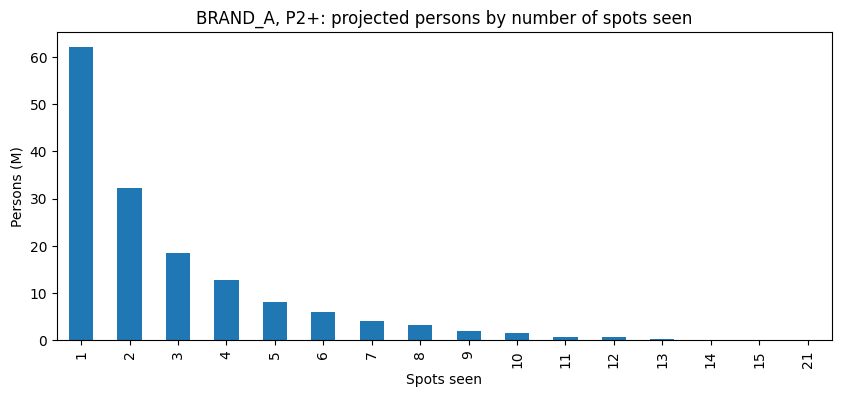

Share of impressions at 5+ exposures: 0.444


In [7]:
freq = exposures.groupby("respondent_id").size().rename("spots_seen").to_frame()
freq["mweight"] = persons["mweight"]
dist = freq.groupby("spots_seen")["mweight"].sum() / 1e6

dist.plot(kind="bar", figsize=(10, 4))
plt.xlabel("Spots seen")
plt.ylabel("Persons (M)")
plt.title("BRAND_A, P2+: projected persons by number of spots seen")
plt.show()

exposures["spots_seen"] = exposures["respondent_id"].map(freq["spots_seen"])
share_5plus = exposures.loc[exposures["spots_seen"] >= 5, "weight"].sum() / exposures["weight"].sum()
print("Share of impressions at 5+ exposures:", round(share_5plus, 3))

**Answer:** Not really. As in Lecture 1 (slide 28), the distribution has a long tail: most reached people saw [1-2] spots, but [X] of impressions went to people with 5+. The average of [F] hides that tail.

## Task 2.3 — On target?

In [8]:
print("Share of impressions on A18-49:", round(t_spots["impressions"].sum() / p2_spots["impressions"].sum(), 3))

net = pd.DataFrame({
    "spots": p2_spots.groupby("network_code").size(),
    "cost_usd": p2_spots.groupby("network_code")["cost"].sum(),
    "P2+ impressions (M)": p2_spots.groupby("network_code")["impressions"].sum() / 1e6,
    "A18-49 impressions (M)": t_spots.groupby("network_code")["impressions"].sum() / 1e6,
})
net["share on A18-49"] = net["A18-49 impressions (M)"] / net["P2+ impressions (M)"]
net[["P2+ impressions (M)", "share on A18-49"]].sort_values("share on A18-49").round({"P2+ impressions (M)": 1, "share on A18-49": 3})

Share of impressions on A18-49: 0.194


,P2+ impressions (M),share on A18-49
network_code,,
FNC,57.8,0.047
CBS,89.0,0.154
ABC,94.2,0.180
NBC,41.4,0.189
HIST,12.3,0.202
FOX,76.3,0.242
HGTV,24.7,0.306
FOOD,9.5,0.316
BRAVO,5.1,0.554


**Answer:** A18-49 is about 42% of persons but got [X] of impressions, so the plan [under]-delivered against its target. The main reason is [NETWORKS]: a low A18-49 share and many impressions.

## Task 3.1 — Cost

In [9]:
cost = spots_a["cost"].sum()
print("Campaign cost (USD):", round(cost))
print("P2+ CPM (USD):", round(cost / p2_spots["impressions"].sum() * 1000, 2))
print("P2+ CPP (USD):", round(cost / p2_grps))
print("A18-49 CPM (USD):", round(cost / t_spots["impressions"].sum() * 1000, 2))
print("A18-49 CPP (USD):", round(cost / t_grps))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [10]:
net["P2+ CPM"] = net["cost_usd"] / (net["P2+ impressions (M)"] * 1e6) * 1000
net["A18-49 CPM"] = net["cost_usd"] / (net["A18-49 impressions (M)"] * 1e6) * 1000
net["cost_usd"] = net["cost_usd"].round().astype(int)
(net[["spots", "cost_usd", "P2+ impressions (M)", "P2+ CPM", "A18-49 CPM"]]
 .sort_values("cost_usd", ascending=False)
 .round({"P2+ impressions (M)": 1, "P2+ CPM": 2, "A18-49 CPM": 2}))

,spots,cost_usd,P2+ impressions (M),P2+ CPM,A18-49 CPM
network_code,,,,,
FOX,13,2434700,76.3,31.93,132.03
ABC,29,1625700,94.2,17.26,95.69
CBS,22,1488700,89.0,16.73,108.72
NBC,16,796800,41.4,19.23,101.72
FNC,40,526300,57.8,9.11,193.70
HGTV,39,230000,24.7,9.33,30.45
FOOD,33,96620,9.5,10.19,32.29
FX,38,92200,8.5,10.82,16.61
HIST,37,79640,12.3,6.46,32.05


**Answer:** Most of the money went to [NETWORKS] ([X]% of cost). Cheapest A18-49 CPM: [NETWORK] ([X] USD); most expensive: [NETWORK] ([Y] USD). A cheap spot is not cheap reach, so compare CPM, not price per spot (Lecture 1, slide 23).

## Task 3.3 — Guarantee

In [11]:
GUARANTEE = 150
owed = max(0, GUARANTEE - p2_grps)
print("Guarantee met:", bool(p2_grps >= GUARANTEE))
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", round(owed * cost / p2_grps))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [12]:
def reach_of(spot_ids):
    seen = exposures.loc[exposures["ad_airing_id"].isin(spot_ids), "respondent_id"].unique()
    return persons.loc[seen, "mweight"].sum() / persons["mweight"].sum() * 100

is_big = spots_a["network_code"].isin(BIG)
reach_big = reach_of(spots_a.loc[is_big, "ad_airing_id"])
reach_small = reach_of(spots_a.loc[~is_big, "ad_airing_id"])
reach_all = reach_of(spots_a["ad_airing_id"])
overlap = reach_big + reach_small - reach_all
overlap_indep = reach_big * reach_small / 100
added = reach_all - reach_big
cost_big = spots_a.loc[is_big, "cost"].sum()
cost_small = spots_a.loc[~is_big, "cost"].sum()

print("Reach, big networks (%):", round(reach_big, 1))
print("Reach, small networks (%):", round(reach_small, 1))
print("Reach, whole campaign (%):", round(reach_all, 1))
print("Overlap (%):", round(overlap, 1))
print("Overlap if independent (%):", round(overlap_indep, 1))
print("Reach added by small networks (points):", round(added, 1))
print("Cost per added reach point, small (USD):", round(cost_small / added))
print("Cost per reach point, big (USD):", round(cost_big / reach_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach does not add (Lecture 3, slide 41): combined reach = big + small − overlap, because people reached by both groups count once. Overlap is [X]% vs [Y]% if independent, so small-network viewers are [more] likely to be reached by big networks too (heavy viewers watch everything). Small networks added [Z] points at [A] USD per point vs [B] USD per point on big networks: [expensive / cheap] extra reach.

## Task 5 — How sure are we?

In [13]:
s5 = p2_spots.copy()
s5["panelists"] = exposures.groupby("ad_airing_id").size()
s5["panelists"] = s5["panelists"].fillna(0).astype(int)
n_in_tab = dw.groupby("bday").size()
p = s5["rating"] / 100
s5["se"] = np.sqrt(p * (1 - p) / s5["bday"].map(n_in_tab)) * 100
s5["rel_se"] = s5["se"] / s5["rating"]
s5["big"] = s5["network_code"].isin(BIG)

display(s5.groupby("network_code")
          .agg(median_panelists=("panelists", "median"), median_rel_se=("rel_se", "median"))
          .round(3).sort_values("median_panelists"))
print("Spots seen by no panelist:", int((s5["panelists"] == 0).sum()))
print("Median relative SE, big networks:", round(s5.loc[s5["big"], "rel_se"].median(), 3))
print("Median relative SE, small networks:", round(s5.loc[~s5["big"], "rel_se"].median(), 3))

w_seen = exposures.loc[exposures["respondent_id"].isin(w1834), "ad_airing_id"].unique()
print("W18-34 zero-cell spots:", int((~s5.index.isin(w_seen)).sum()))

,median_panelists,median_rel_se
network_code,,
BRAVO,3.0,0.540
FOOD,5.0,0.423
HIST,5.0,0.460
FX,5.5,0.423
HGTV,11.0,0.301
FNC,31.0,0.164
ABC,57.0,0.123
NBC,68.5,0.115
CBS,69.0,0.113


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** A zero rating means no panelist saw the spot, not zero US viewers: a median small-network spot has [N] panelists, so its rating is noisy (median relative SE [X] vs [Y] on big networks). This is the sparsity error of Lecture 3 (slides 26-27). [K] of 300 spots have no W18-34 panelist, so I would not report W18-34 by spot, only for the whole campaign, by network or week, or for A18-49. The SE is a lower bound, because weighting shrinks the effective sample.

## Bonus

**Answer:** Move 20 spots from [NETWORK], the highest A18-49 CPM ([X] USD), to [NETWORK], one of the lowest ([Y] USD). The same [Z] USD would buy about [N]M more A18-49 impressions, and spreading spots over another network adds new people rather than frequency (Lecture 1, slides 28 and 35). The gain is an estimate: small-network ratings are noisy (Task 5).